<center>
    <img src=https://upload.wikimedia.org/wikipedia/commons/6/6f/Dauphine_logo_2019_-_Bleu.png style=width: 600px;/> 
</center>

<div align="center"><span style="font-family:Arial Black;font-size:33px;color:darkblue"> Master Economie Finance </span></div>


<div align="center"><span style="font-family:Arial Black;font-size:27px;color:darkblue">Index Construction</span></div>

# Definition

A financial index is a statistical indicator that reflects the change in value of a set of financial assets, such as stocks, bonds, or other financial instruments.
It is used to:
- Measure the performance of a given market or sector.
- Serve as a benchmark for financial products (ETFs, index funds, etc.).
- Compare returns between different asset classes.

Examples of well-known financial indices: CAC 40 (France), Stoxx Europe 600 (Europe), S&P 500 (United States).

An index is not a financial instrument in itself, since it cannot be traded (bought or sold). It does not represent a monetary value but rather a reference value. An investor wishing to gain exposure to the risk represented by a given index generally uses an ETF, which is designed to replicate the chosen financial index.

**Index Composition**

Selection criteria: The index groups companies according to factors such as:
- Size (market capitalization)
- Industry sector
- Country or geographic area

Examples: CAC 40: 40 large French companies listed on Euronext Paris, S&P 500: 500 large U.S. companies.

Although thematic indices are the most common, other more complex indices exist. If an investment strategy can be defined based on a set of rules, it can be expressed in the form of an index.

**Weighting Methods**

- Market capitalization weighting: Each company has a weight proportional to its market capitalization.
- Equal weighting: Each company has the same weight in the index at the time of rebalancing.
- Risk-based weighting: Each company is weighted according to its volatility or another risk indicator.

**Calculation of the Index Value**

Once the investment universe is defined and the weighting method chosen, the index value/performance is calculated at set intervals, generally on a daily basis.

**Index Rebalancing** 

Index rebalancing is the process by which the composition or weighting of the securities that make up a stock index is periodically adjusted.
This ensures that the index remains representative of the market or sector it measures. Rebalancing may include:
- Adding new companies that meet the criteria.
- Removing companies that no longer meet the requirements.

Index rebalancing also helps manage weighting drift between rebalancing dates.

The rebalancing frequency is defined before the index is launched; it can be monthly, quarterly, or yearly. Some market events can trigger exceptional rebalancing (e.g., a volatility spike for certain indices based on a quantitative strategy).


# Part I - Import and Retrieval of the Required Data

For this practical work, we will use Yahoo Finance to retrieve financial data. Other free alternatives exist, however: Stooq, Alpha Vantage, Quandl. Alpha Vantage and Quandl, however, require working with APIs.

For those who wish to access the implementation of yfinance, it is available here: https://github.com/ranaroussi/yfinance

In [3]:
!pip install yfinance pandas_datareader pandas numpy matplotlib scipy numba seaborn --quiet

In [5]:
# import of the libraries required for the project
import os
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import datetime as dt
import scipy.stats as st
import textwrap
import pprint

from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
from matplotlib.ticker import FuncFormatter
from pandas_datareader import data as pdr
from typing import Union, Tuple, List, Dict

In [7]:
# Data retrieval via yfinance - understanding how to use the yfinance package

ticker_test = "TTE.PA"
stock = yf.Ticker(ticker_test)

# The variable stock is an object containing numerous data and functionalities.
# To display all the methods and attributes of the object, we can use Python's native function dir().
dir(stock)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_analysis',
 '_data',
 '_download_options',
 '_earnings',
 '_earnings_dates',
 '_expirations',
 '_fast_info',
 '_fetch_ticker_tz',
 '_financials',
 '_fundamentals',
 '_funds_data',
 '_get_ticker_tz',
 '_holders',
 '_isin',
 '_lazy_load_price_history',
 '_message_handler',
 '_news',
 '_options2df',
 '_price_history',
 '_quote',
 '_shares',
 '_tz',
 '_underlying',
 'actions',
 'analyst_price_targets',
 'balance_sheet',
 'balancesheet',
 'calendar',
 'capital_gains',
 'cash_flow',
 'cashflow',
 'dividends',
 'earnings',
 'earnings_dates',
 'earnings_estimate',
 'earnings_history',
 'eps_revisions',
 'eps_tr

In [11]:
# The attribute info allows displaying the main characteristics of the object.
stock_info = stock.info
print("The variable stock_info has the following type ", type(stock_info))
print("")
print("Data available data in the  :\n")
pprint.pprint(stock_info, indent=4, width=80, sort_dicts=False)
print()
# To access one of the info data points, we just need to provide the desired key, since the variable is a dictionary.
print("The free float of ", stock_info.get("longName"), " is ", stock_info.get("floatShares"))

The variable stock_info has the following type  <class 'dict'>

Data available data in the  :

{   'address1': 'Tour Coupole - 2',
    'address2': 'Place Jean Millier Paris la Défense cedex',
    'city': 'Courbevoie',
    'zip': '92078',
    'country': 'France',
    'phone': '33 1 47 44 60 00',
    'website': 'https://www.totalenergies.com',
    'industry': 'Oil & Gas Integrated',
    'industryKey': 'oil-gas-integrated',
    'industryDisp': 'Oil & Gas Integrated',
    'sector': 'Energy',
    'sectorKey': 'energy',
    'sectorDisp': 'Energy',
    'longBusinessSummary': 'TotalEnergies SE, a multi-energy company, produces '
                           'and markets oil and biofuels, natural gas, biogas '
                           'and low-carbon hydrogen, renewables, and '
                           'electricity in France, rest of Europe, and '
                           'internationally. It operates through five '
                           'segments: Exploration & Production, Integrated 

Our first objective is to build a French stock index that tracks the 20 largest French companies in terms of market capitalization over a 10-year period.
To do this, we need to retrieve the following historical data: closing price, market capitalization.

### About the data used in this TD

* **Prices** — the cell below downloads 10 years of daily closing prices with `yf.download(...)` and **overwrites** `close_data_historical_10y.csv`.
  If the download fails (no internet, Yahoo rate limit…), simply skip the cell: the CSV already provided in the folder is the one read in Part II.
* `auto_adjust=True` means prices are **adjusted for splits and dividends**: the returns we compute therefore include dividends (our index will be close to a *total return* index).
* **Number of shares** — Yahoo Finance does not provide historical share counts, so they come from `number_of_shares_data_historical_10y.csv` (one row per date, one column per ticker, dates written **DD/MM/YYYY**). This file stops at **31/12/2024**: once prices and shares are aligned on common dates, our index will therefore end at the end of 2024.
* The two files do not contain exactly the same tickers (e.g. `ATO.PA`, `EDF.PA` only appear in the shares file): this is why we need a cleaning step.

> 💡 Take a minute to look at both files: run `close_data_from_yf.head()` and `number_of_shares_data_historical.head()` in a new cell.

In [5]:
tickers = [
    'ACA.PA',   # Crédit Agricole
    'BN.PA',    # Danone
    'DSY.PA',   # Dassault Systèmes
    'ENGI.PA',  # Engie
    'RMS.PA',   # Hermès
    'KER.PA',   # Kering
    'OR.PA',    # L'Oréal
    'MC.PA',    # LVMH
    'ML.PA',    # Michelin
    'ORA.PA',   # Orange
    'RI.PA',    # Pernod Ricard
    'PUB.PA',   # Publicis Groupe
    'RNO.PA',   # Renault
    'SAF.PA',   # Safran
    'SGO.PA',   # Saint-Gobain
    'SAN.PA',   # Sanofi
    'SU.PA',    # Schneider Electric
    'GLE.PA',   # Société Générale
    'TEP.PA',   # Teleperformance
    'HO.PA',    # Thales
    'TTE.PA',   # TotalEnergies
    'URW.PA',   # Unibail-Rodamco-Westfield
    'DG.PA',    # Vinci
    'VIV.PA',   # Vivendi
    'WLN.PA',   # Worldline
    'AC.PA',    # Accor
    'ALO.PA',   # Alstom
    'ERF.PA',   # Eurofins Scientific
    'EDEN.PA',  # Edenred
    'LI.PA',    # Klépierre
]

# We will download 10 years of historical data for our stock universe.
end_date = dt.datetime.now() - dt.timedelta(days=1)
start_date = end_date - relativedelta(years=10)

input_data_from_yf = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True) #permet la récupération des données suivantes : Close, High, Low, Open, Volume.
close_data_from_yf = input_data_from_yf['Close']
path_to_store_data = os.getcwd()
close_data_from_yf.to_csv(path_to_store_data + '/close_data_historical_10y.csv')

# The number of shares is not available historically in Yahoo Finance. We will therefore use a CSV file containing this information.
number_of_shares_data_historical = pd.read_csv(path_to_store_data +'/number_of_shares_data_historical_10y.csv')

[*********************100%***********************]  30 of 30 completed


# Part II - Index Construction Methodology

## Formula for defining the weights of index constituents

At a rebalancing date $t_0$, for the $N$ selected constituents:

* **Equal weighting**: $w_i = \dfrac{1}{N}$.
* **Market-cap weighting**: $w_i = \dfrac{\text{cap}_i}{\sum_{j=1}^N \text{cap}_j}$, with $\text{cap}_i = P_{i,t_0} \times \text{Shares}_{i,t_0}$ (price × number of shares outstanding).
* **Custom weighting**: compute a score, then normalise: $w_i = \dfrac{\text{score}_i}{\sum_j \text{score}_j}$.

In all cases the weights are positive and **sum to 1**.

## Formula for determining the value of a market-cap weighted index

Official index providers write the index level as a total market capitalisation divided by a **divisor** $D$:

$$
I_t = \frac{\sum_{i=1}^N Q_{i} \, P_{i,t}}{D}
$$

where $Q_i$ is the number of shares of stock $i$ taken into account in the index and $P_{i,t}$ its price. The divisor $D$ is set so that the index starts at its base value (e.g. 100), and is **adjusted at each corporate action or composition change** so that the index level does not jump for reasons that are not market moves (continuity of the index).

## The equivalent "return" formulation used in this TD

Rather than managing a divisor, we chain the **returns** of the index from one rebalancing date $t_k$ to the next $t_{k+1}$:

$$
R_{i}^{(k)} = \frac{P_{i,t_{k+1}}}{P_{i,t_k}} - 1, \qquad
R_{\text{index}}^{(k)} = \sum_{i=1}^N w_{i,t_k} \, R_{i}^{(k)}, \qquad
I_{t_{k+1}} = I_{t_k} \times \left(1 + R_{\text{index}}^{(k)}\right), \qquad I_{t_0} = 100
$$

Both formulations give the same result: with weights $w_{i,t_k}$ fixed at $t_k$, the index behaves exactly like a portfolio holding a fixed quantity of each stock until the next rebalancing (a *buy-and-hold* portfolio, whose weights then drift with prices).

## Eligibility rules and common filters applied when defining the investment universe

Examples:

* Minimum free-float market capitalization
* Minimum average daily volume (ADV)
* ESG criteria (exclusion of tobacco producers, controversial weapons, or companies generating energy from coal)

## Calculation of weights and base value — implementation

### Step 1 — Data cleaning: `clean_data(close_df, shares_df)`

The two DataFrames have the same structure (index = dates, columns = tickers) but not the same tickers nor the same dates. The function must:

* identify the tickers **common** to both DataFrames;
* identify the dates **common** to both DataFrames;
* return the two DataFrames restricted to these tickers and dates (so that `close_df.loc[d, t]` and `shares_df.loc[d, t]` always refer to the same stock on the same day).

```python
# Toy example of an intersection
pd.Index(["A", "B", "C"]).intersection(pd.Index(["B", "C", "D"]))   # -> Index(['B', 'C'])
```

### Step 2 — Market capitalisation: `compute_market_cap(prices, shares_outstanding)`

Inputs are two **dictionaries** `{ticker: value}` for **one given date**, e.g.

```python
prices             = {"MC.PA": 700.0, "OR.PA": 400.0}
shares_outstanding = {"MC.PA": 5.0e8, "OR.PA": 5.3e8}
# expected output  -> {"MC.PA": 3.5e11, "OR.PA": 2.12e11}
```

$$\text{cap}_i = P_i \times \text{Shares}_i$$

Use `dict.get(key, 0)` to read a value safely; a missing value should lead to a market cap of 0 (the stock will then never be selected).

### Step 3 — Selection of the largest capitalisations

On the **initial date**, keep the 20 companies with the highest market capitalisation and store them in a dictionary `top_20_mkt_cap`.

Hint — sorting a dictionary by its values, in descending order:

```python
d = {"A": 3, "B": 10, "C": 7}
sorted(d.items(), key=lambda x: x[1], reverse=True)        # -> [('B', 10), ('C', 7), ('A', 3)]
dict(sorted(d.items(), key=lambda x: x[1], reverse=True)[:2])  # -> {'B': 10, 'C': 7}
```

* `d.items()` gives `(key, value)` pairs, `key=lambda x: x[1]` sorts on the value, `reverse=True` sorts in descending order, `[:20]` keeps the first 20 pairs, `dict(...)` converts back to a dictionary.

### Step 4 — Index weights: `compute_weights(market_caps)`

$$w_i = \frac{\text{cap}_i}{\sum_j \text{cap}_j}$$

With the toy example of Step 2: $w_{MC} = 3.5/(3.5+2.12) \approx 0.623$ and $w_{OR} \approx 0.377$.

### ✅ Sanity checks for this part
* `top_20_mkt_cap` contains exactly 20 tickers;
* every weight is between 0 and 1 and `sum(wgt.values())` is equal to 1 (up to rounding);
* the largest weights belong to the companies you expect (LVMH, L'Oréal, Hermès, TotalEnergies, Sanofi…).

> The output displayed under the next cell comes from a reference run: your numbers may differ slightly because prices are downloaded at run time.

In [6]:
CLOSE_CSV = "close_data_historical_10y.csv"
SHARES_CSV = "number_of_shares_data_historical_10y.csv"

# =============================================================================
# 1) Data cleaning and alignment
# =============================================================================
def clean_data(close_df: pd.DataFrame, shares_df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Align columns and index between *close_df* and *shares_df*.
    Returns DataFrames containing ONLY the common tickers and dates.

    Instructions:
    1. Find the intersection of the columns (tickers) between *close_df* and *shares_df*. Hint: see `.columns.intersection(...)`.
    2. Find the intersection of the common indexes (dates). Hint: same idea with `.index.intersection(...)`.
    3. Filter both DataFrames to keep only these columns and common dates. Hint: see `.loc[rows, columns]`.
    4. Return the two sorted DataFrames. Hint: `.sort_index()`.
    """
    # common_tickers = ...
    # common_dates = ...

    # close_df = ...
    # shares_df = ...

    # return close_df, shares_df
    raise NotImplementedError("Complete clean_data() according to the instructions above")


# =============================================================================
# 2) Market capitalization calculation
# =============================================================================
def compute_market_cap(prices: Dict[str, float], shares_outstanding: Dict[str, float]) -> Dict[str, float]:
    """Compute market capitalization per ticker from two dicts.

    Instructions:
    - Iterate over the tickers present in *prices* (hint: `for ticker in prices:`).
    - Retrieve *close_price* and *shares* (hint: `dict.get(ticker, 0)`).
    - Handle missing values (None/NaN) by treating them as 0 if necessary
      (hint: `pd.isna(x)` is True for both None and NaN).
    - Return a dict {ticker: market_cap_float} with the market cap of all elements.
    """
    # market_cap = {}
    # for ticker in prices:
    #     close_price = ...
    #     shares = ...
    #     market_cap[ticker] = ...
    # return market_cap
    raise NotImplementedError("Complete compute_market_cap()")


# =============================================================================
# 3) Weights calculation
# =============================================================================
def compute_weights(market_caps: Dict[str, float]) -> Dict[str, float]:
    """Compute weights (sum = 1.0) from market caps.

    Instructions:
    - Calculate the total sum `total_mkt_cap` (hint: `sum(market_caps.values())`).
    - For each ticker, weight = value / total_mkt_cap if total_mkt_cap > 0, else 0.
    - Return a dict {ticker: weight}.
    """
    # total_mkt_cap = ...
    # weights = {}
    # for ticker, cap in market_caps.items():
    #     weights[ticker] = ...
    # return weights
    raise NotImplementedError("Complete compute_weights()")


# =============================================================================
# 4) Test of the functions
# =============================================================================
# a) Load the data (given). The first column of each file holds the dates -> index_col=0.
#    dayfirst=True because the shares file writes its dates as DD/MM/YYYY.
close_data_from_yf = pd.read_csv(CLOSE_CSV, index_col=0, parse_dates=True)
number_of_shares_data_historical = pd.read_csv(SHARES_CSV, index_col=0, parse_dates=True, dayfirst=True)

# b) Make the two DataFrames consistent with clean_data()
# close_data_from_yf, number_of_shares_data_historical = ...
# print(f"After cleaning, both DataFrames contain {len(close_data_from_yf.columns)} tickers:\n")
# print(textwrap.fill("   ".join(close_data_from_yf.columns), width=80) + "\n")

# c) Initialize the index composition: take the first available date and build two dicts
#    {ticker: closing price} and {ticker: number of shares} for that date.
#    Hint: close_data_from_yf.index[0] and df.loc[date].to_dict()
# first_date = ...
# close_data_dict = ...
# shares_data_dict = ...

# d) Compute the market capitalizations with compute_market_cap()
# market_cap_dict = ...

# e) We build a "CAC 20": sort the dict of market caps and keep the 20 largest (see the sorting hint above)
# top_20_mkt_cap = ...
# print("The dict containing the top 20 market caps is:\n")
# pprint.pprint(top_20_mkt_cap, indent=4, width=80, sort_dicts=False)

# f) Compute the initial weights of the selected stocks with compute_weights()
# wgt = ...
# print("The dict containing the index's initial weights is:\n")
# pprint.pprint(wgt, indent=4, width=80, sort_dicts=False)

# g) Sanity checks (uncomment once everything above works)
# assert len(top_20_mkt_cap) == 20
# assert abs(sum(wgt.values()) - 1) < 1e-9
# assert all(0 <= w <= 1 for w in wgt.values())

After cleaning, both DataFrames contain 30 tickers:

AC.PA   ACA.PA   ALO.PA   BN.PA   DG.PA   DSY.PA   EDEN.PA   ENGI.PA   ERF.PA
GLE.PA   HO.PA   KER.PA   LI.PA   MC.PA   ML.PA   OR.PA   ORA.PA   PUB.PA
RI.PA   RMS.PA   RNO.PA   SAF.PA   SAN.PA   SGO.PA   SU.PA   TEP.PA   TTE.PA
URW.PA   VIV.PA   WLN.PA

The dict containing the top 20 market caps is:

{   'SAN.PA': 78941720914.18045,
    'OR.PA': 71809015779.75342,
    'MC.PA': 64793438331.09703,
    'TTE.PA': 55435275083.58183,
    'RMS.PA': 31865975631.87683,
    'BN.PA': 26930929324.12079,
    'SAF.PA': 25918841801.681328,
    'DG.PA': 25816011709.24633,
    'SU.PA': 24434819066.369553,
    'ORA.PA': 21604211980.980396,
    'GLE.PA': 20621799155.91793,
    'RI.PA': 19563958592.193604,
    'ENGI.PA': 19454632612.93091,
    'SGO.PA': 18144390160.176315,
    'RNO.PA': 16137720951.612244,
    'ACA.PA': 15333550464.733171,
    'KER.PA': 14269154663.664553,
    'HO.PA': 11084959849.990082,
    'PUB.PA': 9715248403.16391,
    'AC.PA': 86

## Implementation Part 2 – index value calculation and rebalancing

### Why rebalance?

Between two rebalancing dates the index holds a **fixed quantity** of each stock, so the weights **drift**: a stock that rises gains weight, a stock that falls loses weight. Moreover, the ranking of market caps changes over time: a company may leave the top 20 and another one enter it. Rebalancing = **re-selecting the top 20 and resetting the weights** at regular dates.

### Convert the DataFrames to facilitate data manipulation

From the two DataFrames `close_data_from_yf` and `number_of_shares_data_historical`, create two dictionaries that map each date to a sub-dictionary containing the corresponding values for each stock:

```python
close_dict = {
    Timestamp('2016-12-30'): {'AC.PA': 35.2, 'ACA.PA': 8.9, ...},
    Timestamp('2017-01-02'): {'AC.PA': 35.6, 'ACA.PA': 9.0, ...},
    ...
}
close_dict[some_date]            # -> {ticker: price} on that date: exactly the input expected by compute_market_cap()
close_dict[some_date]["MC.PA"]   # -> price of LVMH on that date
```

Hint: a **dict comprehension** `{d: df.loc[d].to_dict() for d in dates}`.

### Defining the rebalancing dates

The rebalancing dates are the **last available trading day of each year** (already coded for you): the price index is grouped by year and, in each group, the maximum date is kept. They are stored in a list `rebalancing_dates` $= [t_0, t_1, \dots, t_K]$.

### Initializing the index

Set the index value to **100** at the first rebalancing date $t_0$. Use a dictionary `portfolio_value = {date: index value}`.

### Annual rebalancing loop

```
   t0 ───────────── t1 ───────────── t2 ─── ...
   │  period 0      │  period 1      │
   select top 20    select top 20
   compute weights  compute weights
   at t0            at t1
```

For each period $[t_k, t_{k+1}]$:

1. Compute market capitalisations **at the start date** $t_k$ (only information available at $t_k$ may be used — otherwise we would introduce a *look-ahead bias*).
2. Select the 20 largest market capitalisations.
3. Compute their relative weights $w_{i,t_k}$.
4. Compute each selected stock's return over the period: $R_i = P_{i,t_{k+1}} / P_{i,t_k} - 1$.
5. Compute the portfolio (index) return: $R_{\text{index}} = \sum_i w_{i,t_k} R_i$ (sum of the **contributions** $w_i R_i$).
6. Update the index value: $I_{t_{k+1}} = I_{t_k}\,(1 + R_{\text{index}})$.

#### Worked example (2 stocks, 1 period)

| Stock | Weight at $t_0$ | $P_{t_0}$ | $P_{t_1}$ | Return | Contribution $w_iR_i$ |
|---|---|---|---|---|---|
| A | 0.60 | 50 | 55 | +10% | +6.0% |
| B | 0.40 | 20 | 19 | −5% | −2.0% |
| **Index** | 1.00 | | | | **+4.0%** |

$I_{t_0} = 100 \Rightarrow I_{t_1} = 100 \times 1.04 = 104$.

### ✅ Sanity checks
* the first value of the series is exactly 100;
* there is one value per rebalancing date (the last date is 31/12/2024, because the shares file stops there);
* the yearly returns of the index (`pv_series.pct_change()`) are of a plausible magnitude (between −30% and +40%).

Index level over time:

2015-12-30    100.000000
2016-12-30    111.916698
2017-12-29    129.332776
2018-12-31    130.808762
2019-12-31    171.745729
2020-12-31    176.830615
2021-12-31    238.321551
2022-12-30    220.589977
2023-12-29    265.658991
2024-12-31    263.569661
dtype: float64


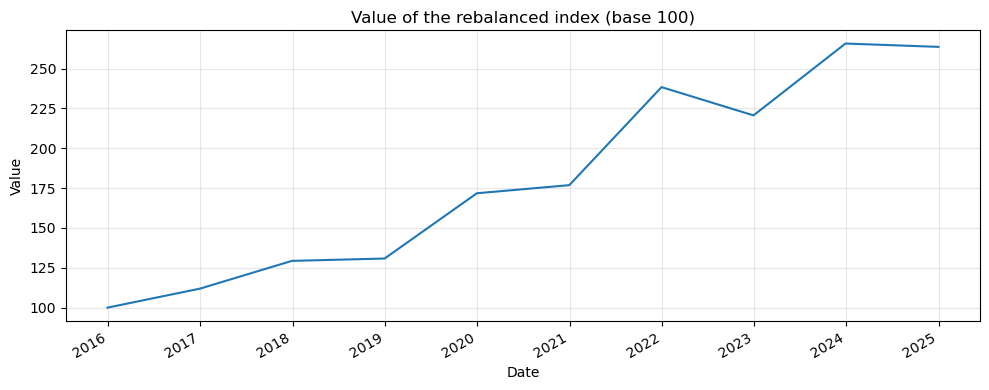

In [7]:
# We now want to extend the index construction to include an annual rebalancing

# Converting the DataFrames to make data manipulation easier:
# close_dict[date] -> {ticker: price}, shares_dict[date] -> {ticker: number of shares}
# dates = ...        # hint: list(close_data_from_yf.index)
# close_dict = ...   # hint: dict comprehension {d: <DataFrame>.loc[d].to_dict() for d in dates}
# shares_dict = ...

# Defining the rebalancing dates: here, the last observation of each year (given)
rebalancing_dates = close_data_from_yf.groupby(close_data_from_yf.index.year).apply(lambda x: x.index.max()).tolist()
if len(rebalancing_dates) < 2:
    raise ValueError("Not enough rebalancing dates to calculate performance.")

# Initialization: retrieve the first rebalancing date and set the index value to 100
portfolio_value = {}
# first_rebalancing_date = ...
# portfolio_value[first_rebalancing_date] = ...

# Loop over each rebalancing period (year by year)
for i, date in enumerate(rebalancing_dates[:-1]):
    start_date = date
    end_date = rebalancing_dates[i+1]

    # Compute market capitalizations at the rebalancing date (use the dicts of start_date only!)
    # mkt_caps = compute_market_cap(..., ...)

    # Select the 20 largest market capitalizations (same sorting trick as in Part 1)
    # top_20 = ...

    # Compute the corresponding weights
    # weights = ...

    # Prices at the start and end of the period for the stocks in the index
    # start_price = ...   # dict {ticker: price} at start_date
    # end_price = ...     # dict {ticker: price} at end_date

    # Compute each stock's contribution to the portfolio return
    # total_contribution = 0.0
    # for ticker in weights:
    #     stock_return = ...           # P_end / P_start - 1
    #     total_contribution += ...    # w_i * R_i

    # Update the portfolio value at the end of the period
    # portfolio_value[end_date] = ...  # I_end = I_start * (1 + R_index)
    pass  # remove this line once the loop body is written


# Convert the dict to a Pandas Series and sort by date
pv_series = pd.Series(portfolio_value).sort_index()
print("Index level over time:\n")
print(pv_series)

# Plot
fig, ax = plt.subplots(figsize=(10, 4))
pv_series.plot(ax=ax)
ax.set_title("Value of the rebalanced index (base 100)")
ax.set_xlabel("Date")
ax.set_ylabel("Value")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Part 3 – Encapsulate the code and make the rebalancing frequency configurable

### Objective

Encapsulate the code of Part 2 into **a single function** and allow the user to choose the **rebalancing frequency** among: *annual*, *quarterly*, *monthly*, *weekly* or *daily*.
We will **reuse as much as possible** from the existing code (dictionary construction, selection/weighting logic, update loop).

### 1. Function signature

Create a function `build_index_with_rebalancing` with the following signature:

* **Inputs**:
  * `close_data_from_yf: pd.DataFrame` (date index, ticker columns, closing prices)
  * `number_of_shares_data_historical: pd.DataFrame` (same structure, number of shares)
  * `frequency: str` in `{"annual", "quarterly", "monthly", "weekly", "daily"}` (default value: `"annual"`)
  * `n_constituents: int` — number of stocks in the index (20 in Part 2: **replace the hard-coded 20 by this parameter**)
  * `base_value: float` — initial index value (100 in Part 2)
  * `return_details: bool` — if `True`, also return the list `details` described in the docstring
* **Outputs**:
  * `pv_series: pd.Series` sorted by date (index value, base 100)
  * and, if `return_details=True`, the tuple `(pv_series, details)`

### 2. Configuring the rebalancing frequency

Set up a **mapping** (a dictionary) between `frequency` and a pandas **period alias**:

| `frequency` | rebalancing date | pandas period alias |
|---|---|---|
| `"annual"` | last trading day of each **year** | `"Y"` |
| `"quarterly"` | last trading day of each **quarter** | `"Q"` |
| `"monthly"` | last trading day of each **month** | `"M"` |
| `"weekly"` | last trading day of each **week** | `"W"` |
| `"daily"` | **every** available day | `"D"` |

Raise a `ValueError` if `frequency` is not one of the keys.

How to get "the last observation of each period" in pandas — the generalisation of the annual code of Part 2:

```python
idx = close_data_from_yf.index
idx.to_period("Q")                              # each date -> the quarter it belongs to, e.g. 2017-03-15 -> 2017Q1
close_data_from_yf.groupby(idx.to_period("Q"))  # one group per quarter
    .tail(1)                                    # last row of each group
    .index                                      # -> the dates we want
```

Try `close_data_from_yf.index.to_period("Q")` alone in a cell to see what it does.

### 3. Index initialization

Set the initial value to `base_value` at the **first** rebalancing date.

### 4. Rebalancing loop (generalize the existing logic)

* Reuse the loop of Part 2 — only the list `rebalancing_dates` changes.
* Robustness: if a start or end price is missing (`None`/`NaN`) or equal to 0, skip the stock (`continue`) instead of crashing.
* If `return_details=True`, append one dictionary per period to `details`, for instance:
  ```python
  {"start": start_date, "end": end_date, "selected": list(weights), "weights": weights,
   "portfolio_return": total_contribution, "value_start": ..., "value_end": ...}
  ```

### 5. Compare the impact of rebalancing frequency on index performance

* Run the function for all frequencies and display the results (code given in the cell after the function).

### Notes

* The financial logic (top 20 by market cap, cap-weighted weights, simple returns) **remains the same**; only the **definition of rebalancing dates** becomes configurable via `frequency`.
* ✅ **Test your function with `frequency="annual"` first: you must obtain exactly the same series as `pv_series` in Part 2.** For instance:
  ```python
  pv_annual = build_index_with_rebalancing(close_data_from_yf, number_of_shares_data_historical, "annual", return_details=False)
  print((pv_annual - pv_series).abs().max())   # should print 0.0 (or something like 1e-13)
  ```
* `"daily"` loops over ~2,000 periods: it is slower, start with the other frequencies.

In [8]:
def build_index_with_rebalancing(
    close_data_from_yf: pd.DataFrame,
    number_of_shares_data_historical: pd.DataFrame,
    frequency: str = "annual",           # "annual" | "quarterly" | "monthly" | "weekly" | "daily"
    n_constituents: int = 20,
    base_value: float = 100.0,
    return_details: bool = True) -> Union[pd.Series, Tuple[pd.Series, List[Dict[str, object]]]]:
    """
    Build the time series of an index rebalanced at the chosen frequency.
    - Prices and number of shares are provided as DataFrames (date index, tickers as columns).
    - The `n_constituents` largest market capitalizations are selected at each rebalancing.
    - Weights are proportional to market capitalizations.

    - If the parameter return_details is True: create a list `details` that stores,
      for each rebalancing period (as a dictionary), the following information:
      start_date, end_date, instruments in the index, each instrument's weight,
      return, initial portfolio value, final portfolio value.

    - The function returns a `pd.Series` with dates and the index value
      (and the list `details` if return_details is True).

    Assumptions: data are clean/aligned, and utility functions are available:
      - compute_market_cap(close_row_dict, shares_row_dict) -> dict{ticker: cap}
      - compute_weights(top_caps_dict) -> dict{ticker: weight}
    """

    # 1) Convert DataFrames -> dictionaries (reuse the code of Part 2)
    # dates = ...
    # close_dict = ...
    # shares_dict = ...

    # 2) Define the rebalancing dates (last observed day of each period)
    # freq_map = {"annual": "Y", "quarterly": ..., "monthly": ..., "weekly": ..., "daily": ...}
    # if frequency not in freq_map:
    #     raise ValueError(...)
    # rebalancing_dates = ...   # hint: groupby(index.to_period(alias)).tail(1).index
    # if len(rebalancing_dates) < 2:
    #     raise ValueError("Not enough rebalancing dates to compute performance.")

    # 3) Initialization
    # portfolio_value = {}
    # portfolio_value[...] = float(base_value)
    # details = []

    # 4) Rebalancing loop over each period (copy the body of the Part 2 loop, replace 20 by n_constituents)
    # for i, start_date in enumerate(rebalancing_dates[:-1]):
    #     end_date = rebalancing_dates[i + 1]
    #     ...
    #     if return_details:
    #         details.append({...})

    # 5) Output
    # pv_series = pd.Series(portfolio_value).sort_index()
    # if return_details:
    #     return pv_series, details
    # return pv_series
    raise NotImplementedError("Complete build_index_with_rebalancing()")

Preview of index values (all frequencies):
                annual   quarterly     monthly      weekly
2015-12-30  100.000000  104.311219  104.306592  104.006543
2016-12-30  111.916698  116.802912  116.772719  116.128238
2017-12-29  129.332776  135.032147  134.983945  134.241540
2020-12-31  176.830615  183.853272  184.969877  183.495919
2021-12-31  238.321551  247.914005  249.675066  248.599443
2022-12-30  220.589977  229.700604  231.128472  229.225422
2023-12-29  265.658991  276.561012  278.436123  276.179564
2024-12-31  263.569661  274.419225  276.273511  274.037761

Table of annual performances (%):
      annual quarterly monthly  weekly
2016  11.92%    11.98%  11.95%  11.65%
2017  15.56%    15.61%  15.60%  15.60%
2018   1.14%     1.16%   1.15%  -0.19%
2019  31.30%    31.57%  31.66%  34.58%
2020   2.96%     2.30%   2.90%   1.76%
2021  34.77%    34.84%  34.98%  35.48%
2022  -7.44%    -7.35%  -7.43%  -7.79%
2023  20.43%    20.40%  20.47%  20.48%
2024  -0.79%    -0.77%  -0.78%  -0.78%


/var/folders/l7/pj1hlfdd0ps42whw_xck619m0000gn/T/ipykernel_27284/1127896184.py:35: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(perf_df.applymap(lambda x: f"{x:.2%}"))


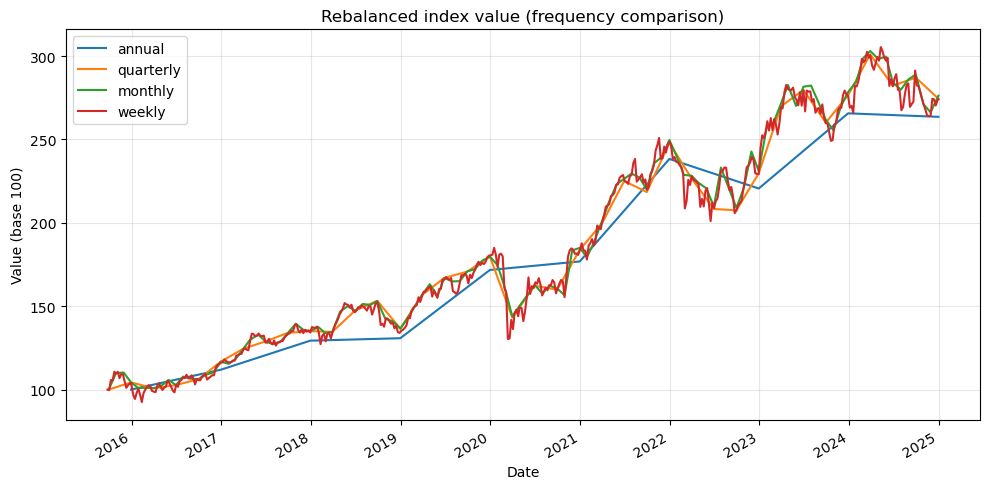

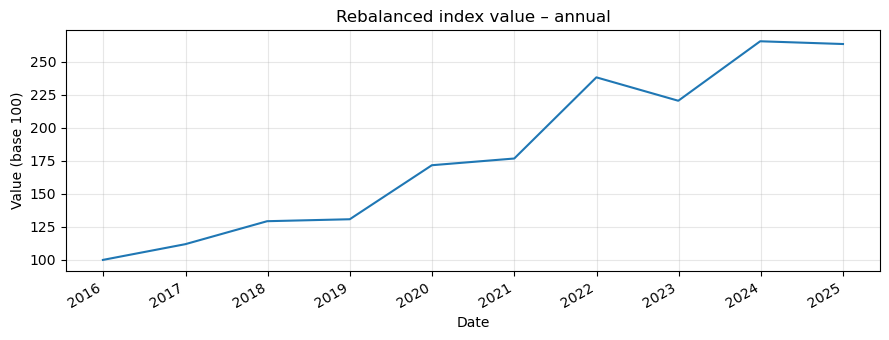

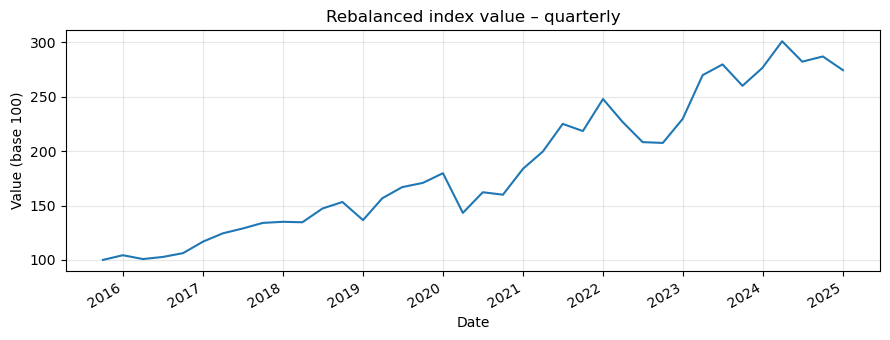

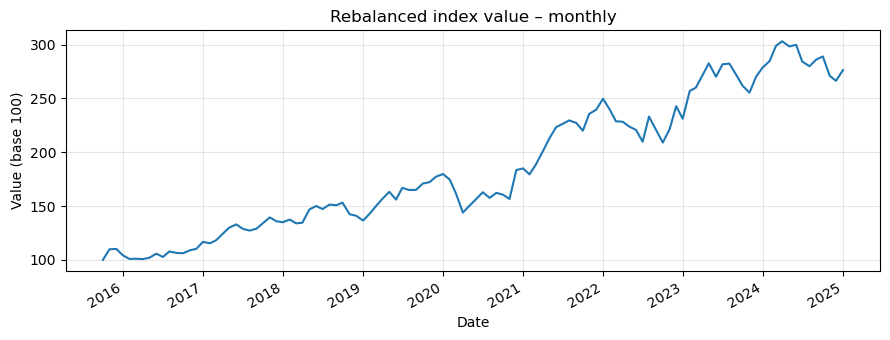

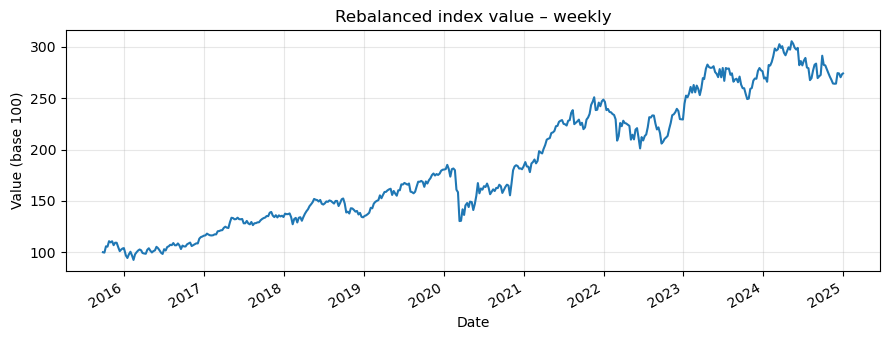

In [9]:
frequencies = ["annual", "quarterly", "monthly", "weekly"]
results = {} 
details_log = {}

# Build the index for each rebalancing frequency
for freq in frequencies:
    pv_series, details = build_index_with_rebalancing(
        close_data_from_yf=close_data_from_yf,
        number_of_shares_data_historical=number_of_shares_data_historical,
        frequency=freq,
        n_constituents=20,
        base_value=100.0,
        return_details=True
    )
    results[freq] = pv_series
    details_log[freq] = details

# Combine into a DataFrame for comparison
pv_df = pd.concat(results, axis=1)  # multi-index columns (freq, series)
pv_df.columns = pv_df.columns.droplevel(1) if isinstance(pv_df.columns, pd.MultiIndex) else pv_df.columns
pv_df = pv_df.sort_index()

print("Preview of index values (all frequencies):")
print(pv_df.dropna())

# Annual performance calculation
annual_perf = {}
for freq, ser in results.items():
    yearly = ser.groupby(ser.index.year).last().pct_change().dropna()
    annual_perf[freq] = yearly

perf_df = pd.DataFrame(annual_perf)

print("\nTable of annual performances (%):")
print(perf_df.apply(lambda col: col.map(lambda x: f"{x:.2%}")))  # format each value as a percentage

# Plot comparison of all frequencies
plt.figure(figsize=(10, 5))
for freq, ser in results.items():
    ser.plot(label=freq)
plt.title("Rebalanced index value (frequency comparison)")
plt.xlabel("Date")
plt.ylabel("Value (base 100)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Individual plots per frequency
for freq, ser in results.items():
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ser.plot(ax=ax)
    ax.set_title(f"Rebalanced index value – {freq}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Value (base 100)")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## Reading the results and going further

### ⚠️ A comparison pitfall: the starting dates differ

The first rebalancing date depends on the frequency: the last day of the first **year** (end of December), but the last day of the first **month** or **week** of the sample (end of November, or a few days after the start of the data). Each series is worth 100 at **its own** start date, so in the table above the monthly and weekly indices are no longer at 100 on the first annual date. To compare the frequencies fairly, **rebase all the series to 100 on a common date** (next cell).

Likewise, the last date of a year is not the same for every frequency (e.g. with a weekly rebalancing the last week of 2018 ends in January 2019), which explains some differences in the table of annual performances.

### Questions

1. After rebasing, which frequency gives the highest final value? Is the gap large? Why are the paths so close to each other?
2. Look at `details_log["annual"]`: which stocks enter and leave the top 20 over time? How do the weights of the largest stocks evolve?
3. A more frequent rebalancing means more trades. What would be the impact of **transaction costs** (e.g. 0.10% of the traded amount)? Which frequency would suffer the most?
4. Our index uses dividend-adjusted prices: is it a *price* index or a *total return* index? What does the CAC 40 (price index) vs the CAC 40 GR (gross total return) correspond to?
5. Modify the code to build an **equally-weighted** top-20 index and compare it with the cap-weighted one.

In [ ]:
# Rebase every series to 100 on a common starting date to compare the frequencies fairly
common_start = max(ser.index[0] for ser in results.values())   # latest of the first dates
rebased = pd.DataFrame({freq: ser[ser.index >= common_start] for freq, ser in results.items()})
rebased = rebased.ffill().dropna()                             # carry the last known value between rebalancing dates
rebased = 100 * rebased / rebased.iloc[0]                      # divide each series by its value on the first common row

print(f"Common start date: {rebased.index[0].date()}")
print("Final value of each index (base 100 at the common start date):")
print(rebased.iloc[-1].round(2))

rebased.plot(figsize=(10, 5), title="Rebased index values (base 100 at a common date)")
plt.ylabel("Value (base 100)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()